
# Практическая работа № 5
## Классификатор и анализ метрик — вариант B

### Цель работы
Построить модель бинарной классификации, оценить её качество
и подобрать порог классификации с учётом стоимости ошибок.

### Используемые методы
- Logistic Regression
- Confusion Matrix
- Precision, Recall, F1-score
- ROC-кривая и ROC-AUC
- Precision-Recall кривая и PR-AUC
- Подбор порога классификации

### Датасет
Breast Cancer Wisconsin из библиотеки scikit-learn.

### Цена ошибок
Для учебного эксперимента стоимость ложноотрицательной ошибки
(FN) принимается равной 5, а ложноположительной (FP) — 1.

Это условное допущение для демонстрации выбора порога.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

print("Библиотеки успешно импортированы!")


Библиотеки успешно импортированы!


In [2]:
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Размер датасета:", X.shape)
print("\nКоличество классов:")
print(y.value_counts().sort_index())

print("\nНазвания классов:")
print(dict(enumerate(data.target_names)))

display(X.head())


Размер датасета: (569, 30)

Количество классов:
target
0    212
1    357
Name: count, dtype: int64

Названия классов:
{0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


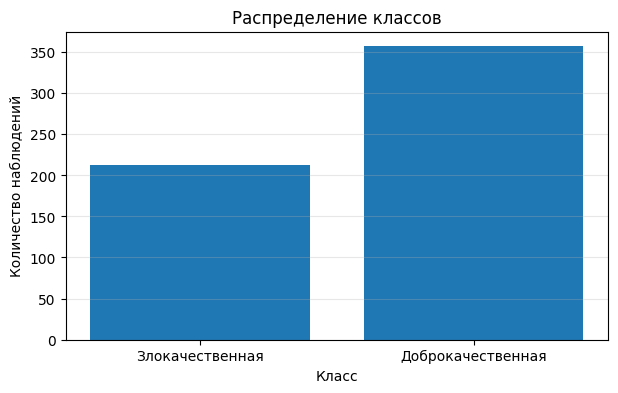

Доля злокачественных случаев: 0.373
Доля доброкачественных случаев: 0.627


In [3]:

class_counts = y.value_counts().sort_index()

class_names = ["Злокачественная", "Доброкачественная"]

plt.figure(figsize=(7, 4))
plt.bar(class_names, class_counts.values)
plt.title("Распределение классов")
plt.xlabel("Класс")
plt.ylabel("Количество наблюдений")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Доля злокачественных случаев:", round((y == 0).mean(), 3))
print("Доля доброкачественных случаев:", round((y == 1).mean(), 3))


In [4]:

y_binary = (y == 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

print("\nКлассы в обучающей выборке:")
print(y_train.value_counts())

print("\nКлассы в тестовой выборке:")
print(y_test.value_counts())


Размер обучающей выборки: (455, 30)
Размер тестовой выборки: (114, 30)

Классы в обучающей выборке:
target
0    285
1    170
Name: count, dtype: int64

Классы в тестовой выборке:
target
0    72
1    42
Name: count, dtype: int64


In [5]:

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=10000, random_state=42))
])

model.fit(X_train, y_train)

print("Модель успешно обучена!")


Модель успешно обучена!


In [6]:

y_proba = model.predict_proba(X_test)[:, 1]
y_pred_default = (y_proba >= 0.5).astype(int)

print("Первые 10 вероятностей:")
print(np.round(y_proba[:10], 3))

print("\nПервые 10 предсказаний:")
print(y_pred_default[:10])


Первые 10 вероятностей:
[0.    1.    0.043 0.576 0.509 0.001 0.762 0.001 0.001 0.011]

Первые 10 предсказаний:
[0 1 0 1 1 0 1 0 0 0]


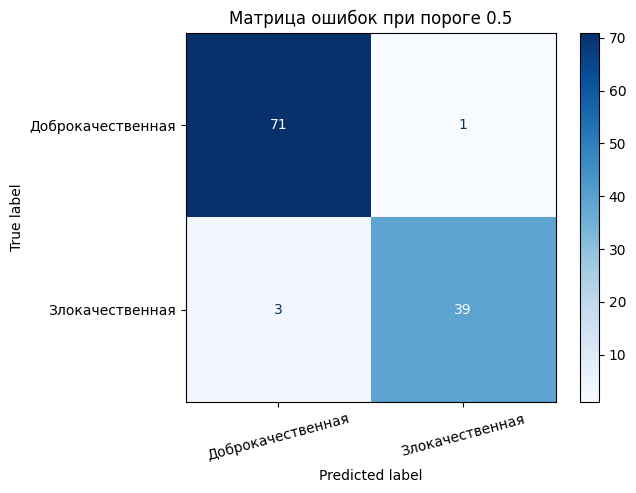

TN: 71
FP: 1
FN: 3
TP: 39


In [7]:

cm = confusion_matrix(y_test, y_pred_default)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Доброкачественная", "Злокачественная"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Матрица ошибок при пороге 0.5")
plt.xticks(rotation=15)
plt.show()

tn, fp, fn, tp = cm.ravel()

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)


In [8]:

metrics_default = {
    "Accuracy": accuracy_score(y_test, y_pred_default),
    "Precision": precision_score(y_test, y_pred_default, zero_division=0),
    "Recall": recall_score(y_test, y_pred_default, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_default, zero_division=0)
}

pd.DataFrame(
    metrics_default.items(),
    columns=["Метрика", "Значение"]
).round(4)


,Метрика,Значение
0,Accuracy,0.9649
1,Precision,0.9750
2,Recall,0.9286
3,F1-score,0.9512


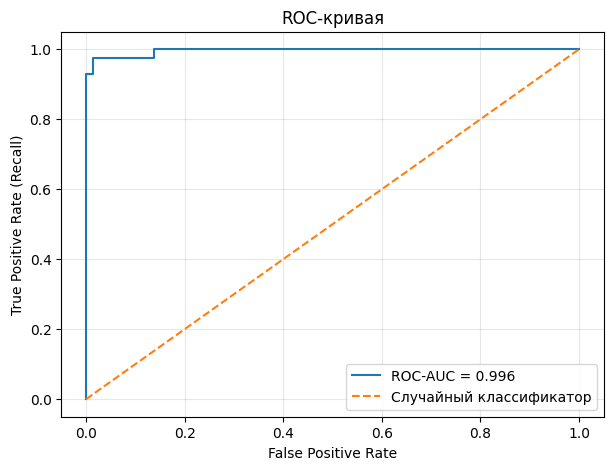

ROC-AUC: 0.9960


In [9]:

fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Случайный классификатор")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-кривая")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")


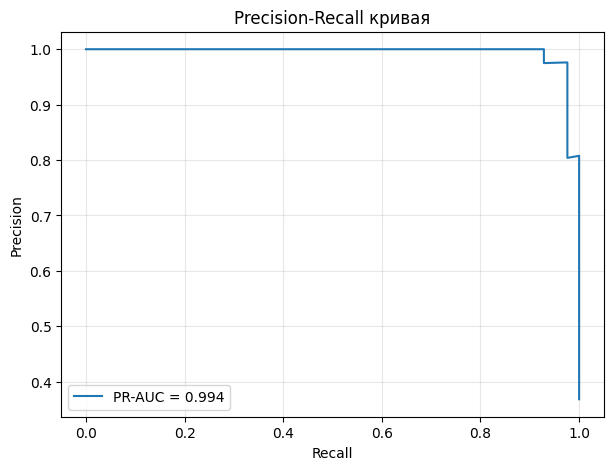

PR-AUC (Average Precision): 0.9943


In [10]:

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test, y_proba
)

pr_auc = average_precision_score(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(recall_values, precision_values, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall кривая")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"PR-AUC (Average Precision): {pr_auc:.4f}")


In [ ]:

COST_FN = 5
COST_FP = 1

thresholds = np.arange(0.05, 0.96, 0.01)

results = []

for threshold in thresholds:
    y_pred = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    cost = COST_FN * fn + COST_FP * fp

    results.append({
        "threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Cost": cost
    })

results_df = pd.DataFrame(results)

best_row = results_df.loc[results_df["Cost"].idxmin()]
best_threshold = best_row["threshold"]


print("Лучший порог:", round(best_threshold, 2))
print("Минимальная стоимость ошибок:", int(best_row["Cost"]))

print(best_row.to_frame("Значение"))


Лучший порог: 0.24
Минимальная стоимость ошибок: 6
           Значение
threshold   0.24000
TN         71.00000
FP          1.00000
FN          1.00000
TP         41.00000
Precision   0.97619
Recall      0.97619
F1          0.97619
Cost        6.00000


In [17]:

y_pred_best = (y_proba >= best_threshold).astype(int)

comparison = pd.DataFrame([
    evaluate_threshold(y_test, y_pred_default, "0.50"),
    evaluate_threshold(y_test, y_pred_best, round(best_threshold, 2))
])

print(comparison.round(4).to_string(index=False))


Порог  Accuracy  Precision  Recall     F1  TN  FP  FN  TP  Стоимость ошибок
 0.50    0.9649     0.9750  0.9286 0.9512  71   1   3  39                16
 0.24    0.9825     0.9762  0.9762 0.9762  71   1   1  41                 6


In [18]:

def evaluate_threshold(y_true, y_pred, name):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Порог": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Стоимость ошибок": COST_FN * fn + COST_FP * fp
    }

print("Функция создана!")


Функция создана!


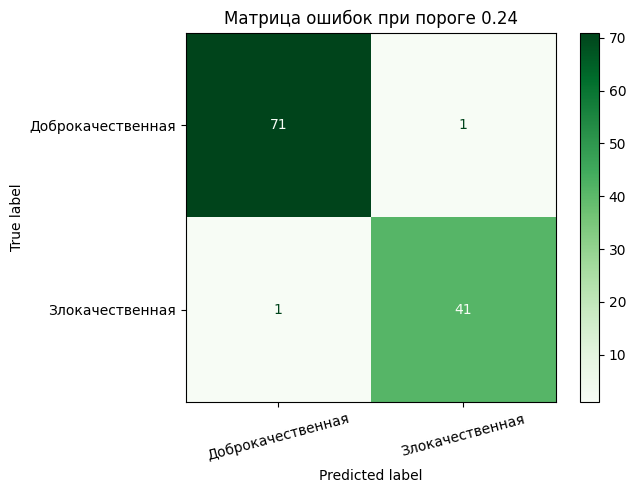

In [19]:

cm_best = confusion_matrix(y_test, y_pred_best, labels=[0, 1])

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=["Доброкачественная", "Злокачественная"]
)

cm_display.plot(cmap="Greens", values_format="d")
plt.title(f"Матрица ошибок при пороге {best_threshold:.2f}")
plt.xticks(rotation=15)
plt.show()


In [20]:

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")


ROC-AUC: 0.9960
PR-AUC: 0.9943



## Выводы

В ходе практической работы была обучена модель Logistic Regression для бинарной классификации на датасете Breast Cancer Wisconsin.

Для оценки качества модели использовались Accuracy, Precision, Recall, F1-score, ROC-AUC и PR-AUC. Были построены ROC-кривая, Precision-Recall кривая и матрицы ошибок.

В учебном эксперименте стоимость FN принята равной 5, а стоимость FP — 1. При подборе порога минимальная стоимость ошибок составила 6 при пороге 0.24.

При данном пороге получены результаты: TN = 71, FP = 1, FN = 1, TP = 41. Precision, Recall и F1-score равны примерно 0.9762.

Эксперимент показывает, что порог классификации влияет на количество ошибок. При более высокой стоимости FN важно уделять особое внимание Recall и количеству пропущенных положительных случаев.

Стоимость ошибок является условным учебным допущением. Для независимой итоговой оценки модели порог следует выбирать на валидационной выборке, а тестовую использовать для финальной проверки.
